# OpenEquivariance E/F training and evaluation

Experiment 04 compared with Experiment 02, including held-out test evaluation. Analysis dated 5 November 2026.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'nmr_helpers').is_dir())
sys.path.insert(0, str(ROOT))
import nmr_helpers

DATA = ROOT / 'experiments/04-EF-Pretrain-TensorBackbone-OpenEquivariance-data'
RUNS = {
    '02': '02-EF-Pretrain-TensorBackbone-9246027',
    '04': '04-EF-Pretrain-TensorBackbone-OpenEquivariance-9265688',
}
LABELS = {'02': 'Experiment 02 · e3nn', '04': 'Experiment 04 · OpenEquivariance'}
COLORS = {'02': '#bd5c51', '04': '#247a85'}
audits = {label: json.loads((DATA / f'audit-{label}.json').read_text()) for label in RUNS}
history = {label: pd.DataFrame(json.loads((DATA / f'history-{label}.json').read_text()))
           for label in RUNS}
metadata = json.loads((DATA / 'run-metadata.json').read_text())
torch.set_num_threads(2)
torch.set_default_dtype(torch.float32)
torch.set_float32_matmul_precision('highest')

configs = {label: yaml.safe_load((ROOT / 'graph-pes-results' / run_id / 'train-config.yaml').read_text())
           for label, run_id in RUNS.items()}
normalised = {}
for label, cfg in configs.items():
    clone = json.loads(json.dumps(cfg))
    clone['general'].pop('run_id', None)
    clone['wandb'].pop('name', None)
    clone['fitting']['loader_kwargs']['batch_size'] = 1
    clone['fitting']['trainer_kwargs']['accumulate_grad_batches'] = 4
    model_key = '+nmr_helpers.tensor_ef_pretraining.TensorCompatibleEFNequIP'
    clone['model']['nequip'][model_key].pop('use_openequivariance', None)
    normalised[label] = clone
assert normalised['02'] == normalised['04']
assert all(a['batch_size'] * a['accumulation'] == 4 for a in audits.values())
assert all(metadata[label]['gpu'] == 'NVIDIA L40S' for label in RUNS)
print('Both runs used one NVIDIA L40S, 800 fitting structures, 50 validation structures, and four structures/update.')
print(pd.DataFrame([
    {'Run': label, 'Batch': a['batch_size'], 'Accumulation': a['accumulation'],
     'Best epoch': a['best_epoch'], 'Last epoch': a['last_epoch'],
     'Last LR': a['final_lr'], 'Checks since best': a['checks_since_best']}
    for label,a in audits.items()
]).to_string(index=False))

Both runs used one NVIDIA L40S, 800 fitting structures, 50 validation structures, and four structures/update.
Run  Batch  Accumulation  Best epoch  Last epoch  Last LR  Checks since best
 02      1             4          43          44 0.003000                  1
 04      2             2         291         306 0.000983                 15


## Training speed and validation progress

Speed statistics use the common epoch window 6–44, excluding the first five epochs. Epoch time is the interval between consecutive validation logs. Time per optimiser update comes from consecutive training logs within the same epoch. Both measures use W&B runtime and include the operations between those logs. Installation before W&B started is outside this timing.

Faint lines show each validation check; solid lines show the best loss reached so far.

Experiment 02 used batch 1 / accumulation 4 and Experiment 04 used 2 / 2. The measured speedup therefore compares the two execution recipes. Experiment 03 showed no clear speed gain from batching alone.

In [2]:

valid_history = {}
speed_rows = []
for label, frame in history.items():
    validation = frame.dropna(subset=['valid/loss/total', 'epoch']).copy()
    validation['Epoch'] = validation['epoch'] + 1
    validation['Seconds per epoch'] = validation['_runtime'].diff()
    validation['Minutes'] = validation['_runtime'] / 60
    valid_history[label] = validation
    common = validation['epoch'].between(5, 43)
    train = frame.dropna(subset=['timer/step_duration_ms/train', 'trainer/global_step', 'epoch']).copy()
    elapsed = train['_runtime'].diff()
    updates = train['trainer/global_step'].diff()
    within_epoch = train['epoch'].eq(train['epoch'].shift()) & train['epoch'].between(5,43) & updates.gt(0)
    speed_rows.append({
        'Run': label,
        'Median seconds/epoch': validation.loc[common, 'Seconds per epoch'].median(),
        'Median seconds/update': (elapsed[within_epoch] / updates[within_epoch]).median(),
        'Median ms/batch': train.loc[train['epoch'].between(5,43),'timer/step_duration_ms/train'].median(),
        'Median ms/validation structure': validation.loc[common,'timer/step_duration_ms/valid'].median() / audits[label]['batch_size'],
    })
speed_table = pd.DataFrame(speed_rows).set_index('Run')
print(speed_table.to_string(float_format=lambda x:f'{x:.3f}'))
epoch_speedup = speed_table.loc['02','Median seconds/epoch'] / speed_table.loc['04','Median seconds/epoch']
update_speedup = speed_table.loc['02','Median seconds/update'] / speed_table.loc['04','Median seconds/update']
print(f'Epoch throughput gain: {epoch_speedup:.2f}×. Optimiser-update throughput gain: {update_speedup:.2f}×.')

progress_rows = []
for label, data in valid_history.items():
    progress_rows.append({
        'Run':label, 'Best loss in first 44 epochs':data.loc[data['epoch']<44,'valid/loss/total'].min(),
        'Best loss over saved run':data['valid/loss/total'].min(),
        'Saved epochs':audits[label]['last_epoch'],
        'Last logged loss':data.iloc[-1]['valid/loss/total'],
    })
print(pd.DataFrame(progress_rows).to_string(index=False,float_format=lambda x:f'{x:.6f}'))


     Median seconds/epoch  Median seconds/update  Median ms/batch  Median ms/validation structure
Run                                                                                              
02                403.453                  1.982          485.000                         134.760
04                 56.697                  0.276          127.000                          24.700
Epoch throughput gain: 7.12×. Optimiser-update throughput gain: 7.19×.
Run  Best loss in first 44 epochs  Best loss over saved run  Saved epochs  Last logged loss
 02                      0.320426                  0.320426            44          0.798397
 04                      0.284487                  0.088132           306          0.098829


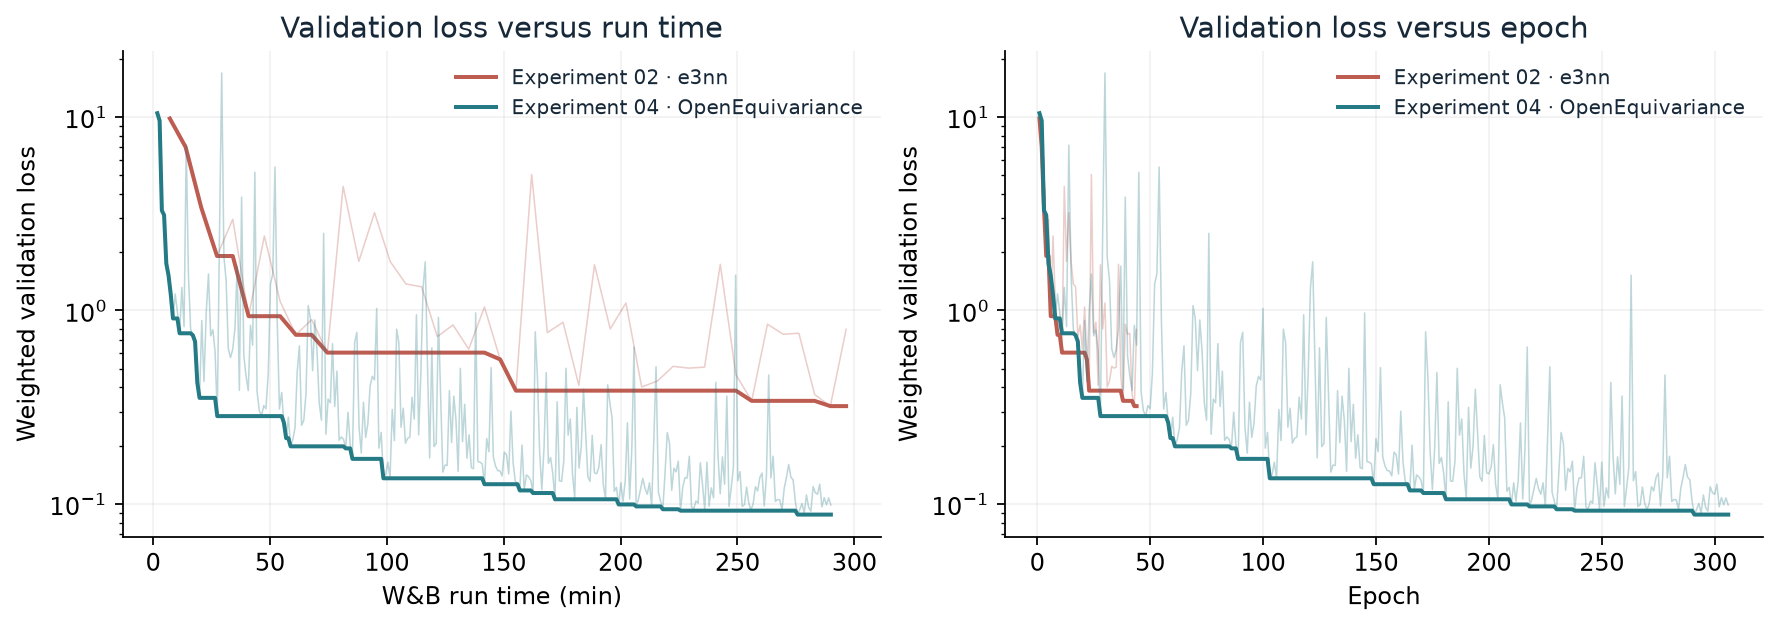

In [3]:

plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
                     'figure.facecolor':'white','text.color':'#172839'})
fig,axes = plt.subplots(1,2,figsize=(11,3.8),layout='constrained')
for label,data in valid_history.items():
    for ax,x in zip(axes,('Minutes','Epoch')):
        ax.plot(data[x],data['valid/loss/total'],color=COLORS[label],alpha=0.3,lw=0.7)
        ax.plot(data[x],data['valid/loss/total'].cummin(),color=COLORS[label],lw=1.8,label=LABELS[label])
for ax,title,xlabel in zip(axes,
                          ('Validation loss versus run time','Validation loss versus epoch'),
                          ('W&B run time (min)','Epoch')):
    ax.set(yscale='log',title=title,xlabel=xlabel,ylabel='Weighted validation loss')
    ax.grid(alpha=0.16)
    ax.legend(frameon=False,fontsize=9)
plt.show()


## Validation parity

Evaluate the checkpoint selected by minimum validation loss in each run on the same 50 structures. Predictions are recomputed on CPU. Experiment 04 uses the sign conversion described below to reproduce its OpenEquivariance training convention. The cache records the best-checkpoint and validation-file hashes. Set RECOMPUTE to True to regenerate it.

Energy metrics use one value per structure in meV/atom. Force metrics pool signed x, y and z components over all atoms. The same validation DFT mean energy is subtracted from both energy axes. R² is 1 − SSE/SST over the reference values in each panel.

### Tensor-product phase compatibility

The direct e3nn CPU fallback for Experiment 04 gives loss 0.3060, compared with the recorded GPU value 0.0881. The released OpenEquivariance 0.3.0 coefficient tables and e3nn 0.4.4 differ by an overall minus sign for couplings (1,2,2), (2,1,2), and (2,2,1). The analysis copy multiplies the corresponding radial weights by −1 on CPU to reproduce the trained function. Original checkpoint files retain their original contents. All 15 angular couplings up to l=2 were checked against the released 0.3.0 source tables; source hashes and residuals are retained in phase-conventions.json in the analysis data folder. This also means the original backend swap changed the initial function at equal weights. The speed comparison remains measured, but the original run is not a strict backend-equivalence ablation.

In [4]:

RECOMPUTE = False

def apply_training_phase_on_cpu(model):
    import e3nn
    assert e3nn.__version__ == '0.4.4', 'Recheck phase conventions for this e3nn version'
    flipped_couplings = {(1,2,2),(2,1,2),(2,2,1)}
    for layer in model.models['nequip'].layers:
        tp = layer.message_tensor_product
        signs = torch.ones(tp.weight_numel)
        offset = 0
        for instruction in tp.instructions:
            size = int(np.prod(instruction.path_shape))
            signature = (tp.irreps_in1[instruction.i_in1].ir.l,
                         tp.irreps_in2[instruction.i_in2].ir.l,
                         tp.irreps_out[instruction.i_out].ir.l)
            if signature in flipped_couplings:
                signs[offset:offset+size] = -1
            offset += size
        assert offset == tp.weight_numel
        layer.weight_generator.register_forward_hook(
            lambda module,args,output,signs=signs: output*signs.to(output)
        )


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

predictions = {}
for label,run_id in RUNS.items():
    run = ROOT / 'graph-pes-results' / run_id
    valid = configs[label]['data']['valid']
    validation_file = ROOT / valid['path']
    assert sha256(run/'checkpoints/best.ckpt') == audits[label]['checkpoint_sha256']
    assert sha256(validation_file) == audits[label]['validation_sha256']
    cache_name = 'validation-04-native-phase.npz' if label == '04' else 'validation-02.npz'
    cache = DATA / cache_name
    if RECOMPUTE or not cache.exists():
        frames = read(validation_file, ':')
        model = torch.load(run/'model.pt',map_location='cpu',weights_only=False).eval()
        best = torch.load(run/'checkpoints/best.ckpt',map_location='cpu',weights_only=False)
        expected = {key[6:]:value for key,value in best['state_dict'].items() if key.startswith('model.')}
        assert model.state_dict().keys() == expected.keys()
        for key,value in model.state_dict().items():
            if torch.is_tensor(value):
                torch.testing.assert_close(value,expected[key],rtol=0,atol=0)
        model.requires_grad_(False)
        if label == '04':
            apply_training_phase_on_cpu(model)
        energies,forces = [],[]
        for atoms in frames:
            graph = AtomicGraph.from_ase(atoms,cutoff=float(model.cutoff),property_mapping=valid['property_map'])
            with torch.enable_grad():
                pred = model.predict(graph,['energy','forces'])
            assert all(torch.isfinite(value).all() for value in pred.values())
            energies.append(float(pred['energy']))
            forces.append(pred['forces'].detach().numpy())
        np.savez_compressed(cache,energy=np.array([a.info['QM_energy'] for a in frames]),
                            predicted_energy=np.array(energies),counts=np.array([len(a) for a in frames]),
                            forces=np.concatenate([a.arrays['QM_forces'] for a in frames]),
                            predicted_forces=np.concatenate(forces))
    with np.load(cache) as saved:
        predictions[label] = {key:saved[key] for key in saved.files}
assert audits['02']['validation_sha256'] == audits['04']['validation_sha256']
for key in ('energy','counts','forces'):
    np.testing.assert_array_equal(predictions['02'][key],predictions['04'][key])
for data in predictions.values():
    assert len(data['counts']) == 50
    assert all(np.isfinite(value).all() for value in data.values())

def metrics(reference,prediction):
    reference,prediction = reference.astype(np.float64).ravel(),prediction.astype(np.float64).ravel()
    error = prediction-reference
    return {'N':len(reference),'RMSE':np.sqrt(np.mean(error**2)),'MAE':np.mean(abs(error)),
            'R²':1-np.sum(error**2)/np.sum((reference-reference.mean())**2)}

panels,metric_rows = {},[]
for label,data in predictions.items():
    reference_e = 1000*data['energy']/data['counts']
    predicted_e = 1000*data['predicted_energy']/data['counts']
    centre = reference_e.mean()
    panels[label] = [
        ('Energy per atom','meV/atom',reference_e-centre,predicted_e-centre),
        ('Force components','eV/Å',data['forces'].ravel(),data['predicted_forces'].ravel()),
    ]
    for title,units,reference,prediction in panels[label]:
        metric_rows.append({'Run':label,'Quantity':title,'Units':units,**metrics(reference,prediction)})
metrics_table = pd.DataFrame(metric_rows)
print(metrics_table.to_string(index=False,float_format=lambda x:f'{x:.5f}'))
cpu_losses = {}
for label in RUNS:
    energy_error = metrics_table[(metrics_table.Run==label)&(metrics_table.Quantity=='Energy per atom')].iloc[0].RMSE
    force_error = metrics_table[(metrics_table.Run==label)&(metrics_table.Quantity=='Force components')].iloc[0].RMSE
    cpu_losses[label] = 1000*(energy_error/1000)**2 + 100*force_error**2
    print(f'{label}: recomputed weighted loss {cpu_losses[label]:.6f}, recorded GPU best '
          f'{audits[label]["best_recorded_loss"]:.6f}.')

with np.load(DATA / 'validation-04.npz') as raw:
    raw_export_metrics = [
        {'Mode':'Original CPU fallback','Quantity':'Energy per atom','Units':'meV/atom',
         **metrics(1000*raw['energy']/raw['counts'],1000*raw['predicted_energy']/raw['counts'])},
        {'Mode':'Original CPU fallback','Quantity':'Force components','Units':'eV/Å',
         **metrics(raw['forces'],raw['predicted_forces'])},
    ]
print('Original fallback scores before phase conversion:')
print(pd.DataFrame(raw_export_metrics).to_string(index=False,float_format=lambda x:f'{x:.5f}'))



Run         Quantity    Units     N    RMSE     MAE      R²
 02  Energy per atom meV/atom    50 2.09711 1.73946 0.99964
 02 Force components     eV/Å 21600 0.05627 0.03209 0.99852
 04  Energy per atom meV/atom    50 0.74733 0.59931 0.99995
 04 Force components     eV/Å 21600 0.02961 0.01449 0.99959
02: recomputed weighted loss 0.321039, recorded GPU best 0.320426.
04: recomputed weighted loss 0.088227, recorded GPU best 0.088132.
Original fallback scores before phase conversion:
                 Mode         Quantity    Units     N    RMSE     MAE      R²
Original CPU fallback  Energy per atom meV/atom    50 5.47379 5.31132 0.99757
Original CPU fallback Force components     eV/Å 21600 0.05254 0.03647 0.99871


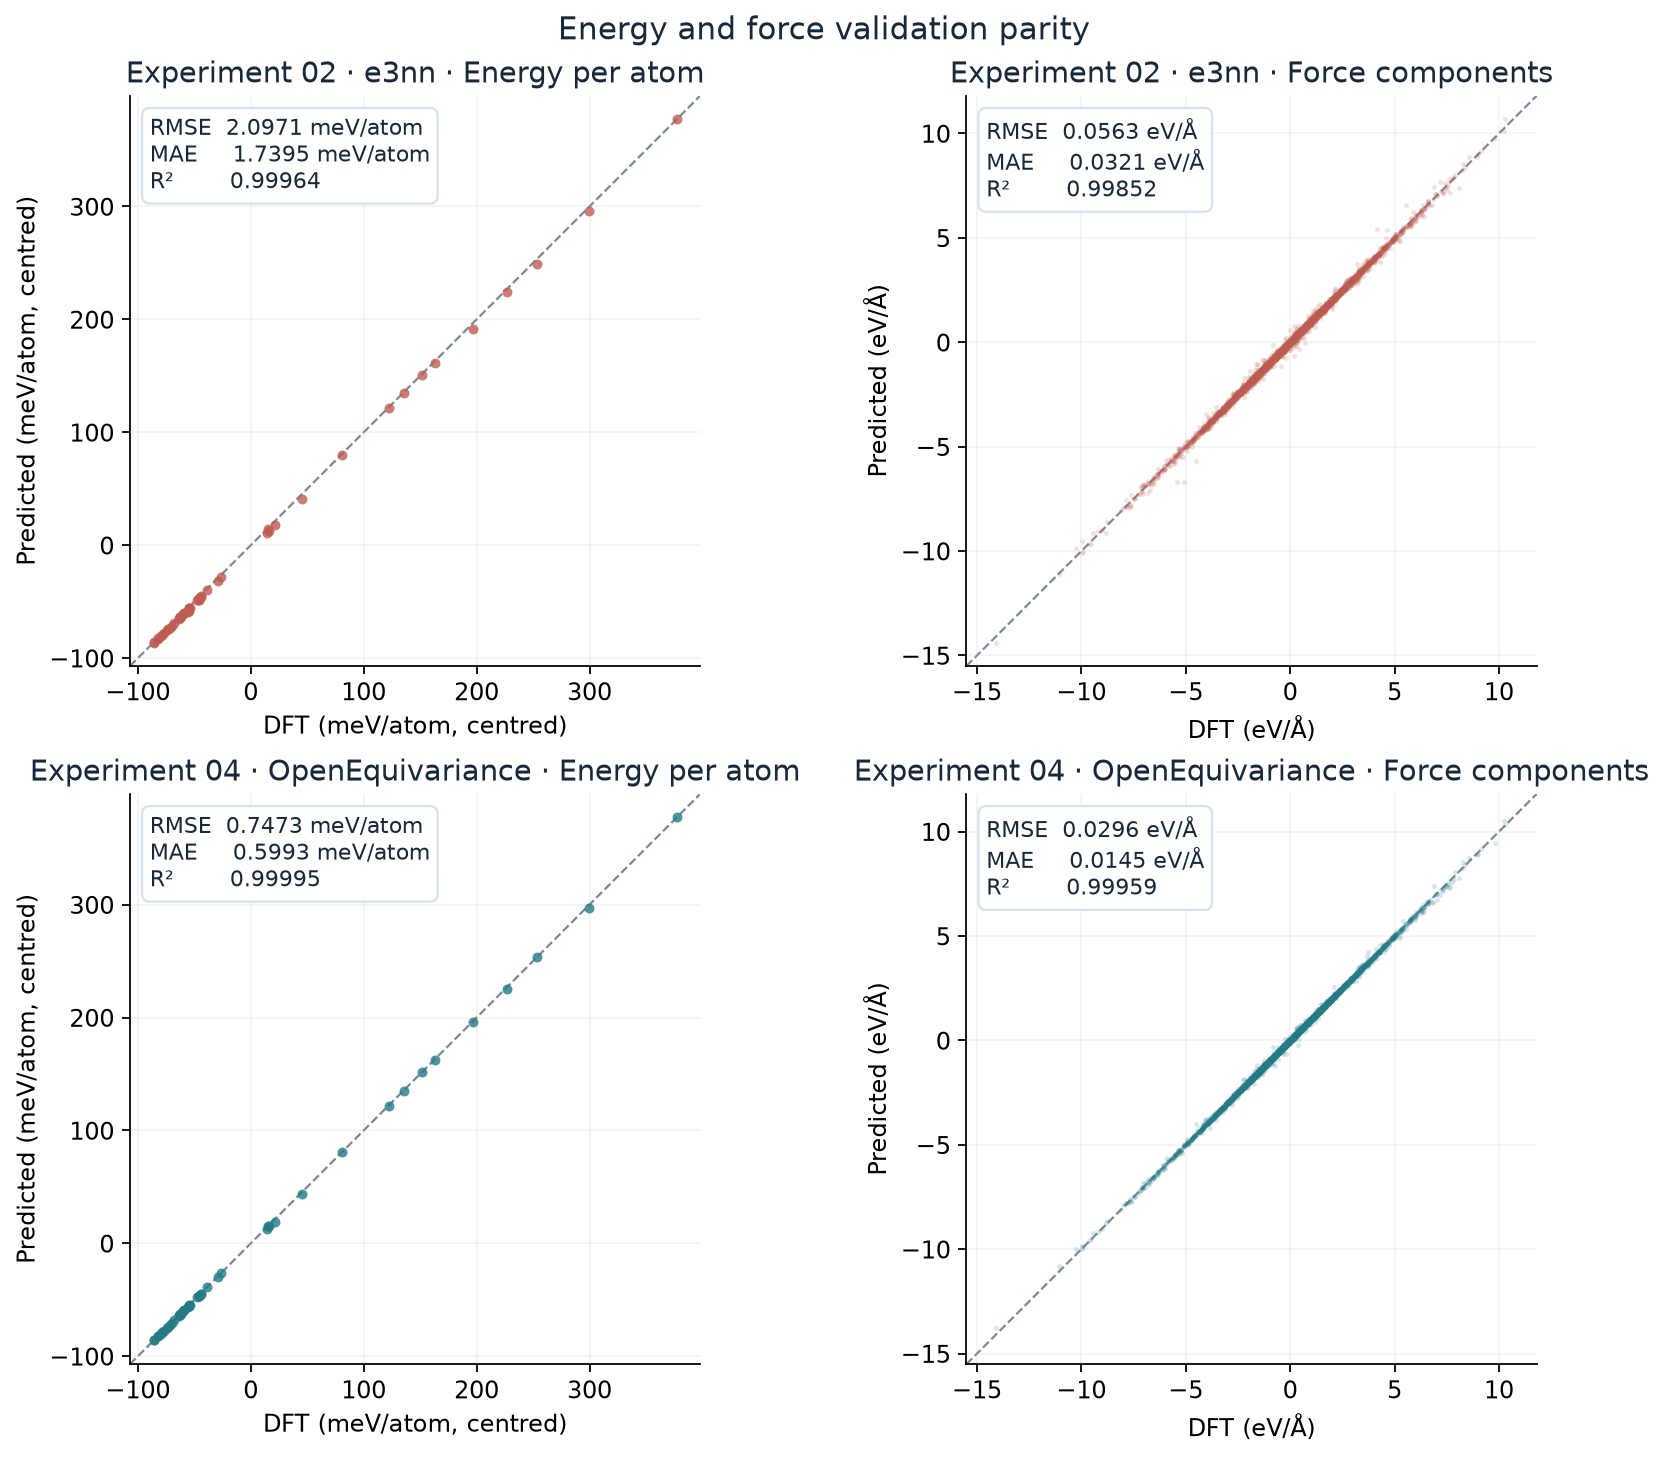

In [5]:

fig,axes = plt.subplots(2,2,figsize=(10.5,9),layout='constrained')
for row,label in enumerate(RUNS):
    for column,(title,units,reference,prediction) in enumerate(panels[label]):
        ax = axes[row,column]
        low = min(min(panels[k][column][2].min(),panels[k][column][3].min()) for k in RUNS)
        high = max(max(panels[k][column][2].max(),panels[k][column][3].max()) for k in RUNS)
        margin = 0.045*(high-low)
        limits = low-margin,high+margin
        ax.plot(limits,limits,'--',lw=1,color='#7c8994',zorder=1)
        ax.scatter(reference,prediction,s=20 if column==0 else 5,
                   alpha=0.8 if column==0 else 0.18,color=COLORS[label],linewidths=0,zorder=2)
        axis_units = 'meV/atom, centred' if column==0 else units
        ax.set(xlim=limits,ylim=limits,title=f'{LABELS[label]} · {title}',
               xlabel=f'DFT ({axis_units})',ylabel=f'Predicted ({axis_units})')
        ax.set_aspect('equal',adjustable='box')
        m = metrics(reference,prediction)
        ax.text(0.035,0.965,f"RMSE  {m['RMSE']:.4f} {units}\n"
                           f"MAE     {m['MAE']:.4f} {units}\n"
                           f"R²        {m['R²']:.5f}",
                transform=ax.transAxes,va='top',fontsize=10,
                bbox=dict(facecolor='white',edgecolor='#d6e0e7',alpha=0.94,boxstyle='round,pad=0.35'))
        ax.grid(alpha=0.13)
fig.suptitle('Energy and force validation parity',fontsize=14)
plt.show()


After phase conversion, Experiment 04 reduced validation energy RMSE by 64.4% and force-component RMSE by 47.4% relative to the best Experiment 02 snapshot. It completed 306 saved epochs within a similar run-time budget, compared with 44 for Experiment 02. The lower final error is consistent with having time for substantially more optimisation. At the common first-44-epoch budget, compare the separate loss values above.

Experiment 04 selected epoch 291. Its final saved learning rate was 0.00098304 and it had 15 validation checks since its best result, against patience 300. Practical convergence remains to be assessed. The copied log ends during best-checkpoint loading and does not include Slurm's termination code. The CPU fallback requires the phase conversion for this checkpoint. Future kernel comparisons and tensor transfer must account for the coefficient convention.

## Held-out test set

Evaluate Experiment 04 at epoch 291, selected by minimum validation loss before test evaluation. All 150 structures in data/test.xyz are scored using the same CPU phase conversion as the validation analysis. The prediction cache and audit record the checkpoint and dataset hashes. Set RECOMPUTE_TEST to True to regenerate the predictions. The table compares this checkpoint on validation and test. Energy errors are in meV/atom; force errors pool signed Cartesian components in eV/Å.

In [6]:

RECOMPUTE_TEST = False
test_audit = json.loads((DATA / 'test-audit-04.json').read_text())
test_file = ROOT / test_audit['test_path']
test_run = ROOT / 'graph-pes-results' / RUNS['04']
assert sha256(test_file) == test_audit['test_sha256']
assert sha256(test_run/'checkpoints/best.ckpt') == test_audit['checkpoint_sha256']
assert test_audit['checkpoint_sha256'] == audits['04']['checkpoint_sha256']
assert test_audit['best_epoch'] == 291
assert all(count == 0 for count in test_audit['geometry_overlaps'].values())
cache = DATA / 'test-04-native-phase.npz'
if RECOMPUTE_TEST or not cache.exists():
    test_frames = read(test_file, ':')
    test_model = torch.load(test_run/'model.pt',map_location='cpu',weights_only=False).eval()
    selected = torch.load(test_run/'checkpoints/best.ckpt',map_location='cpu',weights_only=False)
    selected_state = {key[6:]:value for key,value in selected['state_dict'].items() if key.startswith('model.')}
    assert test_model.state_dict().keys() == selected_state.keys()
    for key,value in test_model.state_dict().items():
        if torch.is_tensor(value):
            torch.testing.assert_close(value,selected_state[key],rtol=0,atol=0)
    test_model.requires_grad_(False)
    apply_training_phase_on_cpu(test_model)
    energies,forces = [],[]
    previous_threads = torch.get_num_threads()
    torch.set_num_threads(test_audit['threads'])
    try:
        for atoms in test_frames:
            graph = AtomicGraph.from_ase(atoms,cutoff=float(test_model.cutoff),
                                         property_mapping=configs['04']['data']['valid']['property_map'])
            with torch.enable_grad():
                predicted = test_model.predict(graph,['energy','forces'])
            assert all(torch.isfinite(value).all() for value in predicted.values())
            energies.append(float(predicted['energy']))
            forces.append(predicted['forces'].detach().numpy())
    finally:
        torch.set_num_threads(previous_threads)
    np.savez_compressed(cache,energy=np.array([a.info['QM_energy'] for a in test_frames]),
                        predicted_energy=np.array(energies),counts=np.array([len(a) for a in test_frames]),
                        forces=np.concatenate([a.arrays['QM_forces'] for a in test_frames]),
                        predicted_forces=np.concatenate(forces))
with np.load(cache) as saved:
    test_predictions = {key:saved[key] for key in saved.files}
assert len(test_predictions['counts']) == test_audit['n_structures'] == 150
assert sum(test_predictions['counts']) == test_audit['n_atoms']
assert all(np.isfinite(value).all() for value in test_predictions.values())
reference_energy = 1000*test_predictions['energy']/test_predictions['counts']
predicted_energy = 1000*test_predictions['predicted_energy']/test_predictions['counts']
test_energy_centre = reference_energy.mean()
test_panels = [
    ('Energy per atom','meV/atom',reference_energy-test_energy_centre,predicted_energy-test_energy_centre),
    ('Force components','eV/Å',test_predictions['forces'].ravel(),test_predictions['predicted_forces'].ravel()),
]
test_metric_rows = [{'Split':'Test','Quantity':title,'Units':units,**metrics(reference,prediction)}
                    for title,units,reference,prediction in test_panels]
validation_metric_rows = [{'Split':'Validation',**{key:value for key,value in record.items() if key!='Run'}}
                          for record in metric_rows if record['Run']=='04']
test_comparison = pd.DataFrame(validation_metric_rows+test_metric_rows).sort_values('Quantity',kind='stable')
print(test_comparison.to_string(index=False,float_format=lambda x:f'{x:.5f}'))
print(f"Checkpoint: epoch {test_audit['best_epoch']}; {test_audit['n_structures']} test structures; "
      f"{3*test_audit['n_atoms']:,} force components.")
print('No test geometry matches in stored training or validation data (atom order retained; 10⁻⁶ Å rounding).')


     Split         Quantity    Units     N    RMSE     MAE      R²
Validation  Energy per atom meV/atom    50 0.74733 0.59931 0.99995
      Test  Energy per atom meV/atom   150 0.88982 0.70059 0.99989
Validation Force components     eV/Å 21600 0.02961 0.01449 0.99959
      Test Force components     eV/Å 64800 0.02303 0.01246 0.99969
Checkpoint: epoch 291; 150 test structures; 64,800 force components.
No test geometry matches in stored training or validation data (atom order retained; 10⁻⁶ Å rounding).


The same test DFT mean energy is subtracted from both energy axes, preserving errors and R². The geometry check detects repeats in the stored atom order; it does not establish independence of parent trajectories.

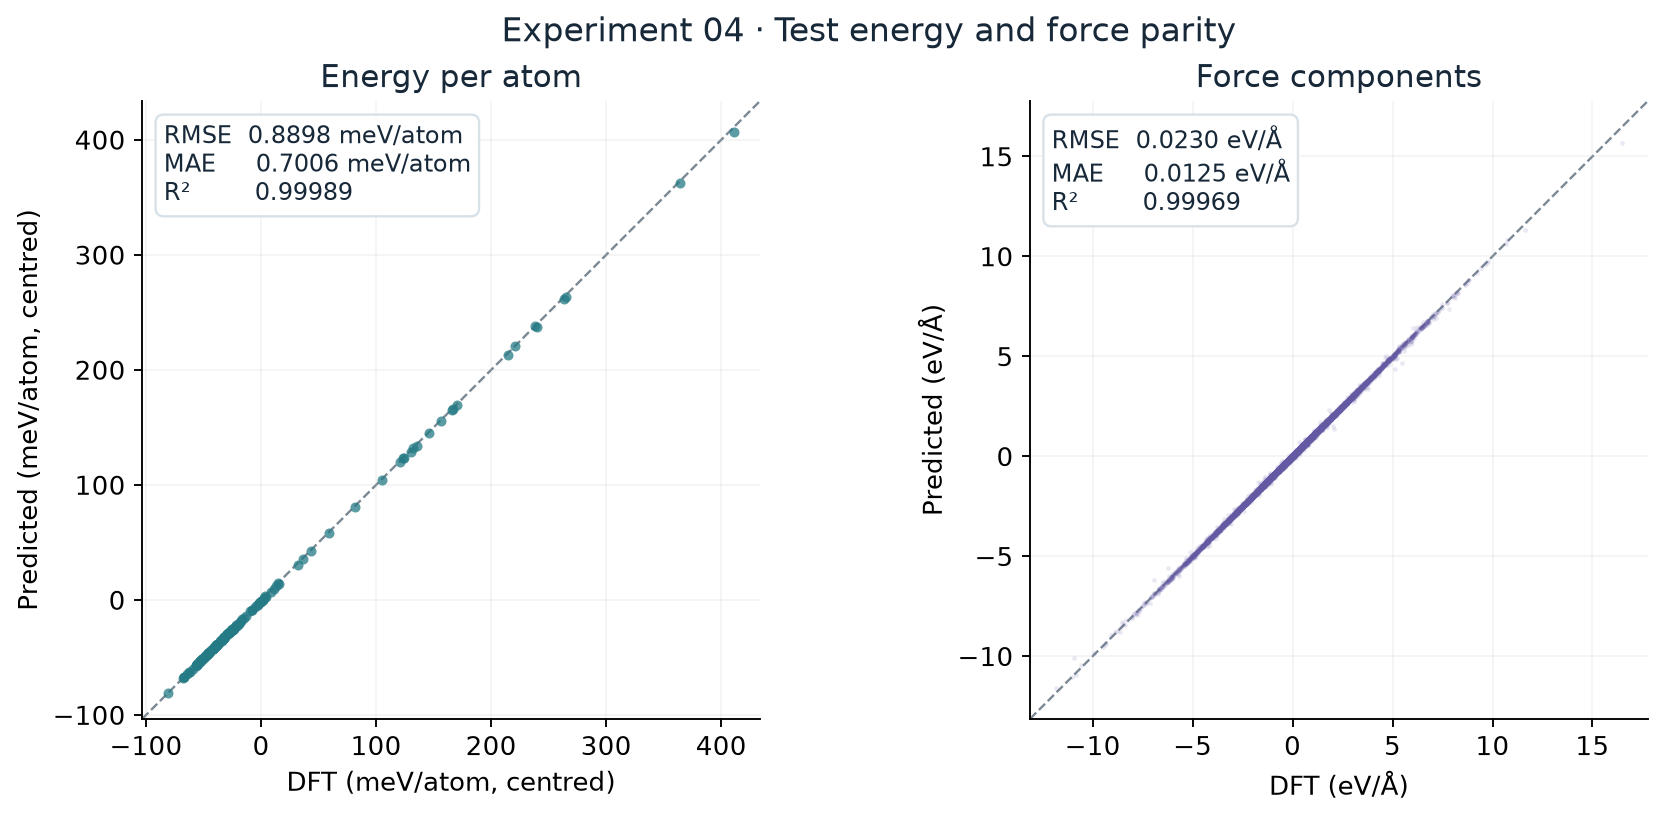

In [7]:

fig,axes = plt.subplots(1,2,figsize=(10.5,4.7),layout='constrained')
for ax,(title,units,reference,prediction),color in zip(axes,test_panels,['#247a85','#6359a5']):
    low = min(reference.min(),prediction.min())
    high = max(reference.max(),prediction.max())
    pad = 0.045*(high-low)
    limits = low-pad,high+pad
    ax.plot(limits,limits,'--',lw=1,color='#7c8994',zorder=1)
    energy_panel = units == 'meV/atom'
    ax.scatter(reference,prediction,s=18 if energy_panel else 4,
               alpha=0.75 if energy_panel else 0.13,color=color,linewidths=0,zorder=2)
    axis_units = 'meV/atom, centred' if energy_panel else units
    ax.set(xlim=limits,ylim=limits,title=title,
           xlabel=f'DFT ({axis_units})',ylabel=f'Predicted ({axis_units})')
    ax.set_aspect('equal',adjustable='box')
    values = metrics(reference,prediction)
    ax.text(0.035,0.965,f"RMSE  {values['RMSE']:.4f} {units}\n"
                       f"MAE     {values['MAE']:.4f} {units}\n"
                       f"R²        {values['R²']:.5f}",
            transform=ax.transAxes,va='top',fontsize=10,
            bbox=dict(facecolor='white',edgecolor='#d6e0e7',alpha=0.94,boxstyle='round,pad=0.35'))
    ax.grid(alpha=0.13)
fig.suptitle('Experiment 04 · Test energy and force parity',fontsize=14)
plt.show()


Test energy RMSE is **0.8898 meV/atom** (+19.1% relative to validation); force-component RMSE is **0.0230 eV/Å** (-22.2% relative to validation). This comparison uses the same validation-selected checkpoint for both splits.

The [Experiment 02 notebook](02-EF-Pretrain-TensorBackbone.ipynb) previously reported test RMSE of 2.1613 meV/atom for energy and 0.04401 eV/Å for force components. Experiment 04's test RMSE is 58.8% lower for energy and 47.7% lower for forces.